# 02 · Repeated Rows, Conflicting Labels and a Fair Split

**The question:** Can repeated rows, conflicting labels or overlap between files make our results look better than they really are,
and how do we split the data so that evaluation stays fair?

| | |
|---|---|
| **Input** | The two raw CSV files |
| **What we do** | Find repeated rows, find rows with identical measurements but different labels, check overlap between the training and testing files, then create a fair split of the training file |
| **Output** | Role assignments (`train`, `model_selection`, `calibration`) in `data/processed/v3/02_roles.csv`, a test overlap marker, tables and figures |

Notebook 01 showed that about 42% of training rows repeat another row's measurements. This notebook explains why that matters
and how we deal with it **before** any model is trained.

## 1. Setup and load the data

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src').is_dir())))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import StratifiedGroupKFold

from src.notebook_helpers import (ROOT, TRAIN_CSV, TEST_CSV, RAW_SHA256, TARGETS, CLASSES, ROLES, DATA,
                                  sha256, save_table, save_figure, save_json, setup_style)
setup_style()

assert {'train': sha256(TRAIN_CSV), 'test': sha256(TEST_CSV)} == RAW_SHA256, 'raw files changed'
train = pd.read_csv(TRAIN_CSV, low_memory=False)
test = pd.read_csv(TEST_CSV, low_memory=False)
predictors = [c for c in train.columns if c not in TARGETS]
print(f'training rows: {len(train):,} | testing rows: {len(test):,} | predictors: {len(predictors)}')

training rows: 175,341 | testing rows: 82,332 | predictors: 42


## 2. What a "repeated row" and a "conflict" mean: a tiny example

Imagine five flows described by only two measurements:

In [2]:
toy = pd.DataFrame({'bytes': [100, 100, 100, 500, 500],
                    'packets': [2, 2, 2, 8, 8],
                    'attack_cat': ['Normal', 'Normal', 'DoS', 'Exploits', 'Exploits']})
toy['pattern'] = toy.groupby(['bytes', 'packets'], sort=False).ngroup()
display(toy)

,bytes,packets,attack_cat,pattern
0,100,2,Normal,0
1,100,2,Normal,0
2,100,2,DoS,0
3,500,8,Exploits,1
4,500,8,Exploits,1


- Rows 0, 1 and 2 have **the same measurements** (pattern 0). That is a **repeated pattern**.
- Inside pattern 0 the labels disagree: two say Normal, one says DoS. That is a **conflict**. No model can get all three right,
  because it sees identical inputs and must give one answer.
- Rows 3 and 4 repeat as well, but they agree (both Exploits).

Two problems follow:

1. **Memorising.** If row 0 is used for training and row 1 for checking, the model has effectively "seen the answer". Scores become too optimistic.
2. **A ceiling.** Conflicts put a hard upper limit on the overall accuracy *any* model can reach.

Below we do the same thing on the real data, using all 42 predictors. We never use `id` or the labels to define a pattern.

## 3. Repeated patterns inside each file

We give every distinct combination of the 42 predictor values a **pattern number**. Rows with the same number are exact repeats.

In [3]:
train['pattern'] = train.groupby(predictors, sort=False).ngroup()
test['pattern'] = test.groupby(predictors, sort=False).ngroup()

def repetition(frame, name):
    size = frame.pattern.map(frame.pattern.value_counts())
    return {'file': name, 'rows': len(frame),
            'distinct patterns': frame.pattern.nunique(),
            'patterns that repeat': int((frame.pattern.value_counts() > 1).sum()),
            'rows inside a repeated pattern': int((size > 1).sum()),
            'extra copies (rows - patterns)': len(frame) - frame.pattern.nunique(),
            'largest pattern (rows)': int(size.max())}

rep = pd.DataFrame([repetition(train, 'training'), repetition(test, 'testing')]).set_index('file')
save_table(rep, '02_repetition_summary', index=True)
display(rep)

,rows,distinct patterns,patterns that repeat,rows inside a repeated pattern,extra copies (rows - patterns),largest pattern (rows)
file,,,,,,
training,175341,101040,9748,84049,74301,415
testing,82332,53946,6318,34704,28386,88


,rows,distinct_patterns,rows per pattern
attack_cat,,,
Generic,40000,4181,9.5671
DoS,12264,3806,3.2223
Exploits,33393,19844,1.6828
Reconnaissance,10491,7522,1.3947
Analysis,2000,1594,1.2547
Backdoor,1746,1535,1.1375
Fuzzers,18184,16150,1.1259
Normal,56000,51890,1.0792
Shellcode,1133,1091,1.0385


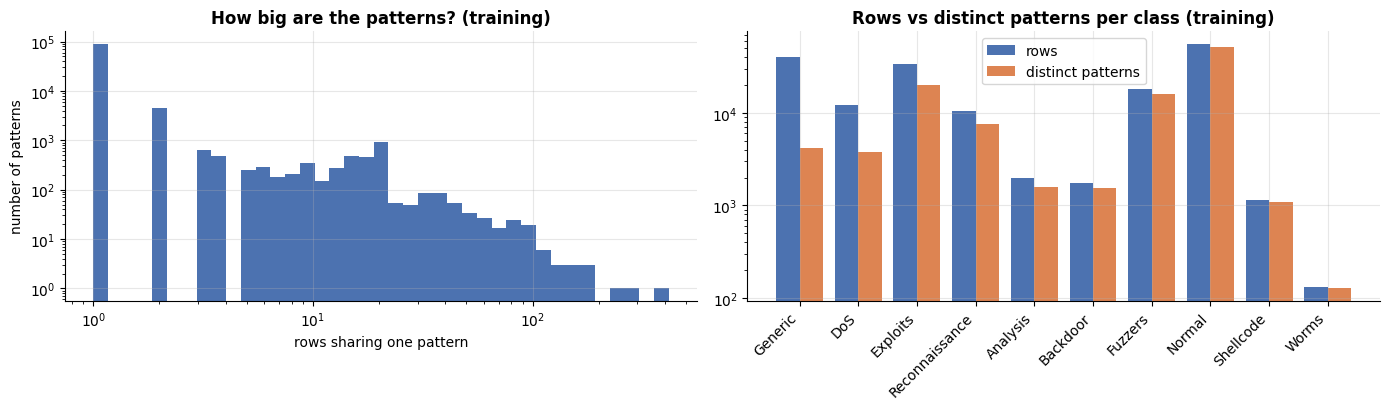

In [4]:
per_class = train.groupby('attack_cat').agg(rows=('pattern', 'size'), distinct_patterns=('pattern', 'nunique')).reindex(CLASSES)
per_class['rows per pattern'] = per_class.rows / per_class.distinct_patterns
per_class = per_class.sort_values('rows per pattern', ascending=False)
save_table(per_class, '02_repetition_by_class', index=True)
display(per_class)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
sizes = train.pattern.value_counts()
axes[0].hist(sizes, bins=np.logspace(0, np.log10(sizes.max() + 1), 40), color='#4C72B0')
axes[0].set(xscale='log', yscale='log', title='How big are the patterns? (training)', xlabel='rows sharing one pattern', ylabel='number of patterns')
x = np.arange(len(per_class))
axes[1].bar(x - 0.2, per_class.rows, 0.4, label='rows', color='#4C72B0')
axes[1].bar(x + 0.2, per_class.distinct_patterns, 0.4, label='distinct patterns', color='#DD8452')
axes[1].set_xticks(x, per_class.index, rotation=45, ha='right')
axes[1].set(yscale='log', title='Rows vs distinct patterns per class (training)')
axes[1].legend()
plt.tight_layout(); save_figure(fig, '02_repetition'); plt.show()

**What we see:**

- The 175,341 training rows contain only **101,040 distinct patterns**. 74,301 rows are extra copies.
- Most patterns appear once, but some appear hundreds of times (the largest 415 times).
- Repetition is very uneven across classes. **Generic** and **DoS** rows are repeated heavily, while Normal rows are almost all different.
  A class with many copies looks "bigger" than its real variety.

## 4. Conflicting labels: same measurements, different answers

For every pattern we count how many different labels it carries. A pattern with more than one label is a **conflict**.
We check both targets: binary (Normal/Attack) and the 10 categories.

In [5]:
def conflicts(frame, name):
    n_cat = frame.groupby('pattern').attack_cat.nunique()
    n_bin = frame.groupby('pattern').label.nunique()
    cat_rows = frame.pattern.isin(n_cat.index[n_cat > 1])
    bin_rows = frame.pattern.isin(n_bin.index[n_bin > 1])
    return {'file': name,
            'patterns with a Normal/Attack conflict': int((n_bin > 1).sum()),
            'rows affected (binary)': int(bin_rows.sum()),
            'patterns with a category conflict': int((n_cat > 1).sum()),
            'rows affected (category)': int(cat_rows.sum()),
            'share of rows affected (category) %': cat_rows.mean() * 100}

conf = pd.DataFrame([conflicts(train, 'training'), conflicts(test, 'testing')]).set_index('file')
save_table(conf, '02_conflict_summary', index=True)
display(conf)

,patterns with a Normal/Attack conflict,rows affected (binary),patterns with a category conflict,rows affected (category),share of rows affected (category) %
file,,,,,
training,229,940,1772,30528,17.4106
testing,6,14,575,8809,10.6994


Which classes get mixed up with each other? For every conflicting pattern we look at each pair of classes inside it.
The heatmap counts how many conflicting patterns contain both classes.

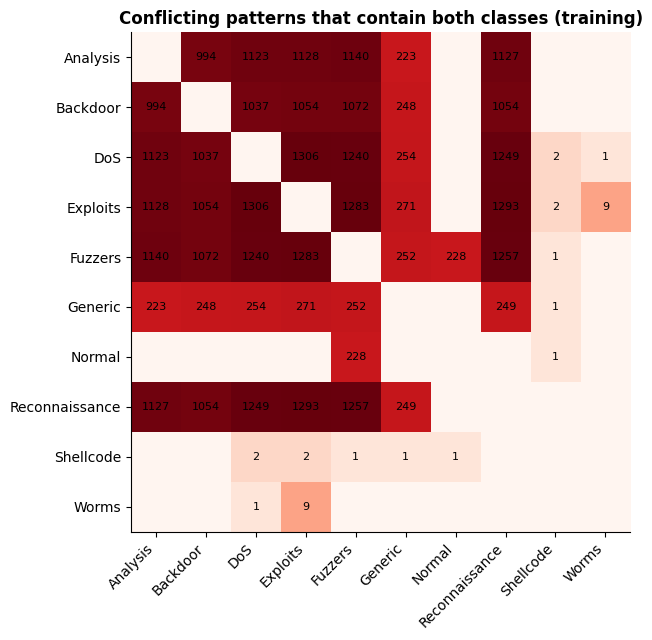

,conflicting patterns
attack_cat,
Analysis + Backdoor + DoS + Exploits + Fuzzers + Reconnaissance,701
Fuzzers + Normal,228
Analysis + Backdoor + DoS + Exploits + Fuzzers + Generic + Reconnaissance,222
Analysis + DoS + Exploits + Fuzzers + Reconnaissance,198
Backdoor + DoS + Exploits + Fuzzers + Reconnaissance,88
DoS + Exploits,68
Analysis + Backdoor,59
Exploits + Reconnaissance,42


In [6]:
cat_sets = train.groupby('pattern').attack_cat.agg(lambda s: sorted(set(s)))
conflict_sets = cat_sets[cat_sets.str.len() > 1]
pairs = pd.DataFrame(0, index=CLASSES, columns=CLASSES)
for labels in conflict_sets:
    for a in labels:
        for b in labels:
            if a != b:
                pairs.loc[a, b] += 1
save_table(pairs, '02_conflict_pairs', index=True)

fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(np.log1p(pairs.values), cmap='Reds')
ax.set_xticks(range(10), CLASSES, rotation=45, ha='right'); ax.set_yticks(range(10), CLASSES)
for i in range(10):
    for j in range(10):
        if pairs.iat[i, j]:
            ax.text(j, i, pairs.iat[i, j], ha='center', va='center', fontsize=8)
ax.set_title('Conflicting patterns that contain both classes (training)'); ax.grid(False)
plt.tight_layout(); save_figure(fig, '02_conflict_heatmap'); plt.show()

combos = conflict_sets.map(' + '.join).value_counts().head(8).rename('conflicting patterns').to_frame()
display(combos)

Here is one real example: the same 42 measurements recorded with different attack categories.

In [7]:
example_pattern = conflict_sets.index[conflict_sets.str.len() >= 3][0]
example = train[train.pattern == example_pattern]
show_cols = ['id', 'proto', 'service', 'state', 'dur', 'sbytes', 'dbytes', 'spkts', 'dpkts', 'sttl', 'attack_cat']
display(example[show_cols].head(8))
print(f'This pattern appears {len(example)} times with labels:', example.attack_cat.value_counts().to_dict())

,id,proto,service,state,dur,sbytes,dbytes,spkts,dpkts,sttl,attack_cat
47956,47957,unas,-,INT,0.0000,200,0,2,0,254,Backdoor
48083,48084,unas,-,INT,0.0000,200,0,2,0,254,Analysis
48088,48089,unas,-,INT,0.0000,200,0,2,0,254,Backdoor
48111,48112,unas,-,INT,0.0000,200,0,2,0,254,Backdoor
51421,51422,unas,-,INT,0.0000,200,0,2,0,254,DoS
51424,51425,unas,-,INT,0.0000,200,0,2,0,254,Exploits
55983,55984,unas,-,INT,0.0000,200,0,2,0,254,Exploits
56035,56036,unas,-,INT,0.0000,200,0,2,0,254,Exploits


This pattern appears 44 times with labels: {'Exploits': 20, 'DoS': 13, 'Backdoor': 4, 'Analysis': 3, 'Reconnaissance': 2, 'Fuzzers': 2}


### The ceiling this creates

If a model saw the training file perfectly and always answered with the **most common label** of each pattern, how often would it be right?
This is the best **overall accuracy** *any* model can reach on these rows: for identical measurements, a model can give only one answer.

Per class we also show the recall of this majority-vote memoriser. That is a useful **reference**, not a strict per-class limit: a model could favour a
minority label inside a conflicting pattern and raise that class's recall, but only by lowering another class's recall by more.

In [8]:
pattern_counts = train.groupby(['pattern', 'attack_cat']).size().sort_values(ascending=False)
majority = pattern_counts.reset_index().drop_duplicates('pattern').set_index('pattern').attack_cat   # most common label per pattern
memoriser = train.pattern.map(majority)                                                         # the memoriser's answer for each row

ceiling = pd.DataFrame({'best possible accuracy %': [(memoriser == train.attack_cat).mean() * 100]}, index=['training file, 10 categories'])
per_class_ceiling = ((memoriser == train.attack_cat).groupby(train.attack_cat).mean() * 100).rename('majority-vote memoriser recall %').sort_values()
save_table(per_class_ceiling.to_frame(), '02_label_ceiling_by_class', index=True)
display(ceiling)
display(per_class_ceiling.to_frame())

,best possible accuracy %
"training file, 10 categories",90.7534


,majority-vote memoriser recall %
attack_cat,
Backdoor,25.2577
Analysis,32.0500
DoS,45.5806
Reconnaissance,82.2896
Fuzzers,91.1736
Exploits,91.4892
Worms,91.5385
Generic,99.2025
Shellcode,99.5587


**What we see:**

- Category conflicts touch **30,528 training rows (17%)**. Binary conflicts are much rarer (940 rows).
  So the measurements separate Normal from Attack well, but often **cannot separate one attack type from another**.
- The most common mix-ups are **DoS, Exploits, Analysis, Backdoor and Reconnaissance** with each other.
- Because of these conflicts, even a perfect memoriser could not get every row right: overall accuracy is capped at about **90.8%**.
  Under majority voting, some classes would be found only rarely (**Backdoor 25%, Analysis 32%, DoS 46%** recall), because their rows share patterns with
  larger classes. When later models struggle with these classes, part of the reason is the labels themselves.

**Decision:** we **do not delete or relabel** these rows. We cannot know which label is "right", and removing them would change the task (section 7).

## 5. Overlap between the training and testing files

If a test row has exactly the same measurements as a training row, a model can recognise it from memory. We find these overlaps
by matching the 42 predictors exactly.

In [9]:
train_patterns = train.drop_duplicates('pattern')[predictors + ['pattern']]
test_patterns = test.drop_duplicates('pattern')[predictors + ['pattern']]
shared = test_patterns.merge(train_patterns, on=predictors, suffixes=('_test', '_train'))

test['in_training_file'] = test.pattern.isin(shared.pattern_test)
train_cats = train.groupby('pattern').attack_cat.agg(set)
test_cats = test.groupby('pattern').attack_cat.agg(set)
shared['labels'] = [train_cats[a] | test_cats[b] for a, b in zip(shared.pattern_train, shared.pattern_test)]
shared['consistent'] = shared.labels.str.len() == 1

overlap = pd.DataFrame({
    'shared distinct patterns': [len(shared)],
    '... with the same single label in both files': [int(shared.consistent.sum())],
    '... with conflicting labels': [int((~shared.consistent).sum())],
    'test rows that also appear in training': [int(test.in_training_file.sum())],
    'test rows that are new': [int((~test.in_training_file).sum())],
})
save_table(overlap.T.rename(columns={0: 'count'}), '02_train_test_overlap', index=True)
display(overlap.T.rename(columns={0: 'count'}))

by_class = test.groupby('attack_cat').in_training_file.agg(['sum', 'size']).reindex(CLASSES)
by_class['% of test rows seen in training'] = by_class['sum'] / by_class['size'] * 100
display(by_class.rename(columns={'sum': 'overlapping rows', 'size': 'test rows'}))

,count
shared distinct patterns,1302
... with the same single label in both files,754
... with conflicting labels,548
test rows that also appear in training,8541
test rows that are new,73791


,overlapping rows,test rows,% of test rows seen in training
attack_cat,,,
Analysis,125,677,18.4638
Backdoor,4,583,0.6861
DoS,2004,4089,49.0095
Exploits,1802,11132,16.1876
Fuzzers,261,6062,4.3055
Generic,1722,18871,9.1251
Normal,1472,37000,3.9784
Reconnaissance,1138,3496,32.5515
Shellcode,13,378,3.4392


**What we see:** 8,541 test rows (about 10%) have an exact twin in the training file. For some classes the share is much higher:
**DoS (49%)**, **Reconnaissance (33%)** and **Analysis (18%)**. Of the 1,302 shared patterns, 548 carry different labels in the two files,
so "having seen it" does not even guarantee the right answer.

**Decision:** we keep the **complete test file** as the official test. Later we will also report results separately for
"seen" and "new" test rows, so we can tell how much of the score comes from recognising known patterns.
We save this marker now, without looking at any model results.

## 6. Columns that need care

A few columns behave in ways worth noting before modelling.

In [10]:
ftp_train_equal = (train.is_ftp_login == train.ct_ftp_cmd).all()
ftp_test_unequal = int((test.is_ftp_login != test.ct_ftp_cmd).sum())
notes = pd.DataFrame([
    ('is_ftp_login and ct_ftp_cmd', f'identical in every training row: {ftp_train_equal}; different in {ftp_test_unequal} test rows',
     'Keep both. They are copies in training but not in testing.'),
    ('is_ftp_login', f"should be 0/1 but has values {sorted(train.is_ftp_login.unique().tolist())} in training",
     'Keep as recorded; do not "fix" values without documentation.'),
    ("service = '-'", f"{(train.service == '-').mean() * 100:.1f}% of training rows",
     'Treat as its own category ("service not identified"), not as missing.'),
    ('ct_* counters', 'counted over the previous ~100 connections',
     'Usable for offline analysis of completed flows; we cannot verify they only use past traffic.'),
    ('id', 'rows are stored sorted by class (Notebook 01)', 'Never an input; not a time order.'),
], columns=['column', 'observation', 'decision'])
save_table(notes, '02_column_notes')
display(notes)

,column,observation,decision
0,is_ftp_login and ct_ftp_cmd,identical in every training row: True; differe...,Keep both. They are copies in training but not...
1,is_ftp_login,"should be 0/1 but has values [0, 1, 2, 4] in t...","Keep as recorded; do not ""fix"" values without ..."
2,service = '-',53.7% of training rows,"Treat as its own category (""service not identi..."
3,ct_* counters,counted over the previous ~100 connections,Usable for offline analysis of completed flows...
4,id,rows are stored sorted by class (Notebook 01),Never an input; not a time order.


## 7. Our policy: keep every row and every label

Should we remove repeats or conflicting rows? The table shows what the two common "cleaning" options would do to each class.

In [11]:
policy = pd.DataFrame({'keep everything (our choice)': train.attack_cat.value_counts(),
                       'drop repeated copies': train.drop_duplicates('pattern').attack_cat.value_counts(),
                       'drop conflicting patterns': train[~train.pattern.isin(conflict_sets.index)].attack_cat.value_counts()}).reindex(CLASSES)
for col in policy.columns[1:]:
    policy[f'{col}: % of class left'] = policy[col] / policy.iloc[:, 0] * 100
save_table(policy, '02_cleaning_options', index=True)
display(policy)

,keep everything (our choice),drop repeated copies,drop conflicting patterns,drop repeated copies: % of class left,drop conflicting patterns: % of class left
attack_cat,,,,,
Analysis,2000,542,559,27.1000,27.9500
Backdoor,1746,513,406,29.3814,23.2532
DoS,12264,3004,2518,24.4945,20.5316
Exploits,33393,18721,20094,56.0626,60.1743
Fuzzers,18184,14889,16106,81.8797,88.5724
Generic,40000,3924,39681,9.8100,99.2025
Normal,56000,51815,55604,92.5268,99.2929
Reconnaissance,10491,6422,8602,61.2144,81.9941
Shellcode,1133,1089,1126,96.1165,99.3822


**What we see:** Dropping conflicting patterns would remove most of **Analysis** and **Backdoor** (only about 28% and 23% left).
Dropping copies would shrink DoS and Generic heavily. Both options would quietly change what we are measuring.

**Decision:** keep all rows and labels exactly as supplied. Instead of cleaning, we make evaluation fair by **keeping identical patterns together**
(next section).

## 8. A fair split of the training file

We need three groups of rows, all taken from the training file:

| Role | Share | Used for |
|---|---|---|
| `train` | 80% | fitting preprocessing and models |
| `model_selection` | 10% | comparing models and settings |
| `calibration` | 10% | kept aside for a later confidence-calibration step |

The testing file stays separate as the final exam.

**The key rule:** all rows with the same pattern go to the **same role**. Otherwise the same measurements could be in `train` and in
`model_selection`, and the model would be graded on rows it has already seen. `StratifiedGroupKFold` does this for us:
"group" keeps patterns together, "stratified" keeps the class shares similar in each role.

The settings (fold 0, seeds 42 and 43) were fixed in advance; we did not try other seeds to get a "nicer" split.

In [12]:
y = train.attack_cat.to_numpy()
groups = train.pattern.to_numpy()

outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
fit_rows, holdout_rows = next(outer.split(np.zeros(len(train)), y, groups))          # 80% / 20%

inner = StratifiedGroupKFold(n_splits=2, shuffle=True, random_state=43)
selection_part, calibration_part = next(inner.split(np.zeros(len(holdout_rows)), y[holdout_rows], groups[holdout_rows]))

train['role'] = 'train'
train.loc[holdout_rows[selection_part], 'role'] = 'model_selection'
train.loc[holdout_rows[calibration_part], 'role'] = 'calibration'
display(train.role.value_counts().reindex(ROLES).to_frame('rows'))

,rows
role,
train,140273
model_selection,17534
calibration,17534


### Check 1: no pattern is in two roles

In [13]:
roles_per_pattern = train.groupby('pattern').role.nunique()
print('Largest number of roles any pattern belongs to:', roles_per_pattern.max())
assert roles_per_pattern.max() == 1

for a, b in [('train', 'model_selection'), ('train', 'calibration'), ('model_selection', 'calibration')]:
    matches = train[train.role == a][predictors].drop_duplicates().merge(train[train.role == b][predictors].drop_duplicates(), on=predictors)
    print(f'exact matches between {a} and {b}: {len(matches)}')
    assert len(matches) == 0

Largest number of roles any pattern belongs to: 1


exact matches between train and model_selection: 0


exact matches between train and calibration: 0
exact matches between model_selection and calibration: 0


### Check 2: the split is identical to the one used by earlier work

The earlier project version saved its split in `results/splits/02_train_validation_assignments.csv`. Ours must be exactly the same,
so every later result stays comparable.

In [14]:
frozen = pd.read_csv(ROOT / 'results/splits/02_train_validation_assignments.csv')
assert (frozen.role.to_numpy() == train.role.to_numpy()).all()
assert (frozen.feature_group_id.to_numpy() == train.pattern.to_numpy()).all()
print('Identical to the frozen split: same role and same pattern number for all', len(train), 'rows.')

Identical to the frozen split: same role and same pattern number for all 175341 rows.


### Check 3: every class is represented fairly in every role

rows                             % of role                             distinct patterns                            
role            train model_selection calibration     train model_selection calibration             train model_selection calibration
attack_cat                                                                                                                           
Analysis         1600             200         200    1.1400          1.1400      1.1400              1274             159         161
Backdoor         1397             175         174    1.0000          1.0000      0.9900              1227             153         155
DoS              9811            1226        1227    6.9900          6.9900      7.0000              3044             382         380
Exploits        26714            3340        3339   19.0400         19.0500     19.0400             15876            1984        1984
Fuzzers         14547            1818        1819   10.3700         10.3700     10.3700             12919            1616        1615
Generic         32000            4000        4000   22.8100         22.8100     22.8100              3342             419         420
Normal          44800            5600        5600   31.9400         31.9400     31.9400             41512            5188        5190
Reconnaissance   8393            1049        1049    5.9800          5.9800      5.9800              6033             912         577
Shellcode         907             113         113    0.6500          0.6400      0.6400               874             108         109
Worms             104              13          13    0.0700          0.0700      0.0700               102              13          12

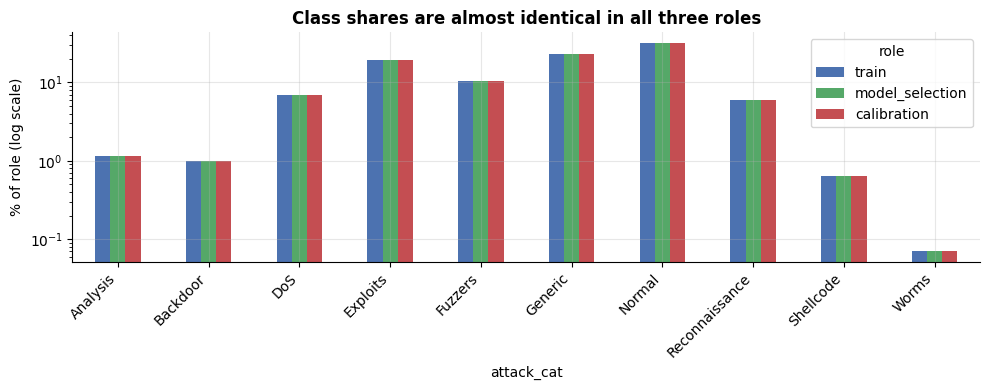

In [15]:
support = pd.crosstab(train.attack_cat, train.role).reindex(index=CLASSES, columns=ROLES)
shares = (support / support.sum() * 100).round(2)
patterns_per_role = train.groupby(['attack_cat', 'role']).pattern.nunique().unstack().reindex(index=CLASSES, columns=ROLES)
table = pd.concat({'rows': support, '% of role': shares, 'distinct patterns': patterns_per_role}, axis=1)
save_table(table, '02_role_class_support', index=True)
display(table)

fig, ax = plt.subplots(figsize=(10, 4))
shares.plot.bar(ax=ax, color=['#4C72B0', '#55A868', '#C44E52'])
ax.set(yscale='log', ylabel='% of role (log scale)', title='Class shares are almost identical in all three roles')
plt.xticks(rotation=45, ha='right'); plt.tight_layout(); save_figure(fig, '02_role_class_shares'); plt.show()

**What we see:** The class shares match across the three roles to within a few hundredths of a percent. Every class appears in every role.
The weak spot is **Worms**: only **13 rows** in `model_selection` and 13 in `calibration`. Any result on Worms will be shaky,
because one extra correct row changes Worms recall by almost 8 percentage points.

## 9. How we will judge models

We fix the scoring rules now, before any model exists, so we cannot pick the rule that flatters a result.

In [16]:
rules = pd.DataFrame([
    ('Main score', 'Macro F1 over all 10 classes', 'Every class counts equally, so rare attacks matter as much as Normal'),
    ('Per class', 'Precision, recall, F1 and support for each class', 'Shows which attacks are missed'),
    ('Mistakes', 'Confusion matrix (counts and row %)', 'Shows which classes get mixed up'),
    ('Attack vs Normal', 'Attack recall, false-positive rate, precision; average precision from 1 - P(Normal)', 'How well attacks are caught and how many false alarms'),
    ('Secondary', 'Accuracy and weighted F1', 'Reported, but never used to choose a model'),
    ('Data roles', 'Fit on train; compare on model_selection; calibration kept aside; test used once at the end', 'Keeps the final score honest'),
    ('Test reporting', 'Full test file, plus "seen in training" vs "new" rows', 'Shows how much the score depends on memorised patterns'),
], columns=['what', 'rule', 'why'])
save_table(rules, '02_evaluation_rules')
display(rules)

,what,rule,why
0,Main score,Macro F1 over all 10 classes,"Every class counts equally, so rare attacks ma..."
1,Per class,"Precision, recall, F1 and support for each class",Shows which attacks are missed
2,Mistakes,Confusion matrix (counts and row %),Shows which classes get mixed up
3,Attack vs Normal,"Attack recall, false-positive rate, precision;...",How well attacks are caught and how many false...
4,Secondary,Accuracy and weighted F1,"Reported, but never used to choose a model"
5,Data roles,Fit on train; compare on model_selection; cali...,Keeps the final score honest
6,Test reporting,"Full test file, plus ""seen in training"" vs ""ne...",Shows how much the score depends on memorised ...


## 10. Save the results

In [17]:
roles_out = train[['id', 'pattern', 'role', 'label', 'attack_cat']].rename(columns={'id': 'source_id'})
roles_out.insert(0, 'row_position', np.arange(len(train)))
roles_out.to_csv(DATA / '02_roles.csv', index=False)

test_out = test[['id', 'pattern', 'in_training_file']].rename(columns={'id': 'source_id'})
test_out.insert(0, 'row_position', np.arange(len(test)))
test_out.to_csv(DATA / '02_test_overlap_marker.csv', index=False)

save_json({'roles_file': 'data/processed/v3/02_roles.csv', 'roles_sha256': sha256(DATA / '02_roles.csv'),
           'test_marker_sha256': sha256(DATA / '02_test_overlap_marker.csv'), 'raw_sha256': RAW_SHA256,
           'split': 'StratifiedGroupKFold: 5 folds seed 42 fold 0 -> holdout; 2 folds seed 43 on holdout -> model_selection / calibration',
           'groups': 'exact equality of all 42 predictors (no id, no labels)'}, DATA / '02_manifest.json')
assert {'train': sha256(TRAIN_CSV), 'test': sha256(TEST_CSV)} == RAW_SHA256
print('Saved roles, test overlap marker and manifest. Raw files unchanged.')

Saved roles, test overlap marker and manifest. Raw files unchanged.


## Summary

### What we learned

| Topic | Finding |
|---|---|
| Repeats | 175,341 training rows hold only 101,040 distinct patterns. Generic and DoS repeat the most |
| Conflicts | 17% of training rows sit in a pattern with more than one attack category. Normal vs Attack conflicts are rare |
| Ceiling | Conflicts cap overall accuracy at about 90.8%; Analysis, Backdoor and DoS suffer most because they share patterns with larger classes |
| Overlap | About 10% of test rows also appear in training (49% of DoS and 33% of Reconnaissance test rows) |
| Policy | Keep every row and label; make evaluation fair by keeping patterns together |
| Split | 140,273 train / 17,534 model_selection / 17,534 calibration rows, no shared patterns, identical to the frozen split |

### What is still uncertain

- Two rows with different patterns are not necessarily independent events (they may come from the same host or attack run). We cannot check this without IP addresses and timestamps.
- Worms has only 13 rows in `model_selection`, so Worms results will be unstable.

### What Notebook 03 does next

Explore the **train** rows in more depth (how each feature relates to each class) and build the **preprocessing**: turning text
columns into numbers and taming the skewed number columns, learned from `train` rows only.